# EDA биржевых данных Bitcoin

Сначала разбираем пятилетние минутные свечи Binance BTC/USDT, затем отдельно смотрим годовой файл и сравниваем цены на общем участке.

Все даты — **UTC**. Файлы лежат в `eda/data`, ноутбук запускается из папки `eda`. Исходные CSV не меняем. Пропущенные цены не заполняем.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)

## 1. Загружаем данные Binance

Одна строка — одна минута. `datetime_utc` показывает начало свечи. OHLC — первая, максимальная, минимальная и последняя цена минуты. `volume_base` — объём BTC, `volume_quote` — объём USDT.

In [2]:
btc = pd.read_csv('data/BTCUSDT_spot_1m_5y.csv')
btc['datetime_utc'] = pd.to_datetime(btc['datetime_utc'], utc=True)
btc.head()

,timestamp,datetime_utc,open,high,low,close,volume_base,volume_quote,last_trade_id
0,1635843540000,2021-11-02 08:59:00+00:00,61695.60,61729.86,61551.47,61565.34,41.99468,2.588680e+06,NaN
1,1635843600000,2021-11-02 09:00:00+00:00,61565.34,61575.77,61565.34,61573.72,13.05269,8.036689e+05,NaN
2,1635843660000,2021-11-02 09:01:00+00:00,61573.72,61600.00,61566.54,61566.54,21.41203,1.318434e+06,NaN
3,1635843720000,2021-11-02 09:02:00+00:00,61566.55,61571.89,61530.88,61537.22,19.93413,1.226909e+06,NaN
4,1635843780000,2021-11-02 09:03:00+00:00,61535.09,61548.99,61528.53,61535.32,12.47028,7.673370e+05,NaN


In [3]:
btc.shape

(2629360, 9)

In [4]:
btc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2629360 entries, 0 to 2629359
Data columns (total 9 columns):
 #   Column         Dtype              
---  ------         -----              
 0   timestamp      int64              
 1   datetime_utc   datetime64[ns, UTC]
 2   open           float64            
 3   high           float64            
 4   low            float64            
 5   close          float64            
 6   volume_base    float64            
 7   volume_quote   float64            
 8   last_trade_id  float64            
dtypes: datetime64[ns, UTC](1), float64(7), int64(1)
memory usage: 180.5 MB


In [5]:
btc['datetime_utc'].agg(['min', 'max'])

min   2021-11-02 08:59:00+00:00
max   2026-11-02 08:58:00+00:00
Name: datetime_utc, dtype: datetime64[ns, UTC]

## 2. Проверяем пропуски и ошибки

Пустой `last_trade_id` у Binance ожидаем: парсер был разработан на основе lighter parser, Binance не отдает такой информации.

In [ ]:
btc.isna().sum()

timestamp              0
datetime_utc           0
open                   0
high                   0
low                    0
close                  0
volume_base            0
volume_quote           0
last_trade_id    2629360
dtype: int64

In [ ]:
print('Полных повторов строк:', btc.duplicated().sum())
print('Повторных дат:', btc['datetime_utc'].duplicated().sum())
print('Даты идут по порядку:', btc['datetime_utc'].is_monotonic_increasing)

Полных повторов строк: 0
Повторных дат: 0
Даты идут по порядку: True


In [ ]:
unix_time = pd.to_datetime(btc['timestamp'], unit='ms', utc=True)
print('Несовпадений двух столбцов времени:', (unix_time != btc['datetime_utc']).sum())

Несовпадений двух столбцов времени: 0


Цены должны быть положительными, объёмы — неотрицательными. Open и close должны находиться между low и high. Ниже выводятся количества нарушений и сами подозрительные свечи.

In [ ]:
(btc[['open', 'high', 'low', 'close']] <= 0).sum()

open     0
high     0
low      0
close    0
dtype: int64

In [ ]:
(btc[['volume_base', 'volume_quote']] < 0).sum()

volume_base     0
volume_quote    0
dtype: int64

In [ ]:
bad_candles = btc[
    (btc['high'] < btc[['open', 'close']].max(axis=1))
    | (btc['low'] > btc[['open', 'close']].min(axis=1))
    | (btc['low'] > btc['high'])
]
bad_candles.head()

,timestamp,datetime_utc,open,high,low,close,volume_base,volume_quote,last_trade_id


В текущем файле повторных дат, пропусков OHLCV и нарушений границ цены нет. Резкие движения цены не удаляем: сами по себе они не являются ошибкой.

## 3. Проверяем минутный шаг и разрывы

Проверяем расстояние между соседними датами. В норме оно равно одной минуте. Таблица ниже показывает первую и последнюю отсутствующую минуту.

In [12]:
step = btc['datetime_utc'].diff()
step.value_counts()

datetime_utc
0 days 00:01:00    2629358
0 days 01:21:00          1
Name: count, dtype: int64

In [13]:
gaps = btc.loc[step > pd.Timedelta(minutes=1), ['datetime_utc']].copy()
gaps['Начало пропуска'] = btc['datetime_utc'].shift(1) + pd.Timedelta(minutes=1)
gaps['Конец пропуска'] = gaps['datetime_utc'] - pd.Timedelta(minutes=1)
gaps['Минут'] = step / pd.Timedelta(minutes=1) - 1
gaps[['Начало пропуска', 'Конец пропуска', 'Минут']]

,Начало пропуска,Конец пропуска,Минут
730301,2023-03-24 12:40:00+00:00,2023-03-24 13:59:00+00:00,80.0


В Binance отсутствуют 80 минут: 24 марта 2023 года с 12:40 по 13:59 UTC. Причину по одному CSV определить нельзя.

Делаем дату индексом и восстанавливаем минутную сетку. В отсутствующих строках останутся NaN.

In [14]:
btc = btc.set_index('datetime_utc')
btc = btc.asfreq('min')
print('Отсутствующих минут:', btc['close'].isna().sum())

Отсутствующих минут: 80


На графике — число записанных минут по месяцам. Крайние месяцы файла неполные; разная длина остальных месяцев тоже влияет на число минут.

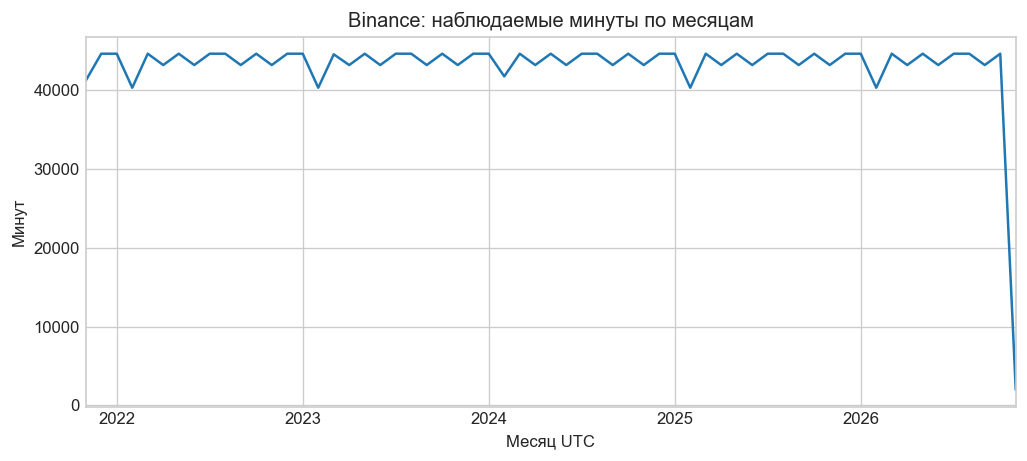

In [15]:
monthly_count = btc['close'].resample('MS').count()
monthly_count.plot()
plt.title('Binance: наблюдаемые минуты по месяцам')
plt.ylabel('Минут')
plt.xlabel('Месяц UTC')
plt.show()

## 4. Готовим часовые и дневные цены

Для часовой цены берём последний close часа. Оставляем его только при наличии всех 60 минут. Метку переносим на конец часа: цена часа 00:00–01:00 становится доступна в 01:00 UTC.

Так же поступаем с четырьмя часами и сутками. Обязательное число минут — 240 и 1440.

In [16]:
hour_count = btc['close'].resample('h').count()
hour_close = btc['close'].resample('h').last()
hour_close = hour_close.where(hour_count == 60)
hour_close.index = hour_close.index + pd.Timedelta(hours=1)
hour_close.head()

datetime_utc
2021-11-02 09:00:00+00:00         NaN
2021-11-02 10:00:00+00:00    63050.62
2021-11-02 11:00:00+00:00    63198.93
2021-11-02 12:00:00+00:00    62913.30
2021-11-02 13:00:00+00:00    62998.32
Freq: h, Name: close, dtype: float64

In [17]:
four_hour_count = btc['close'].resample('4h').count()
four_hour_close = btc['close'].resample('4h').last()
four_hour_close = four_hour_close.where(four_hour_count == 240)
four_hour_close.index = four_hour_close.index + pd.Timedelta(hours=4)

In [18]:
day_count = btc['close'].resample('D').count()
day_close = btc['close'].resample('D').last()
day_close = day_close.where(day_count == 1440)
day_close.index = day_close.index + pd.Timedelta(days=1)

In [19]:
print('Неполных часовых интервалов:', (hour_count < 60).sum())
print('Неполных четырёхчасовых интервалов:', (four_hour_count < 240).sum())
print('Неполных дней:', (day_count < 1440).sum())

Неполных часовых интервалов: 4
Неполных четырёхчасовых интервалов: 3
Неполных дней: 3


## 5. Цена и объём за день

Показываем только полные дни. Неполные крайние дни и день с разрывом остаются пропусками.

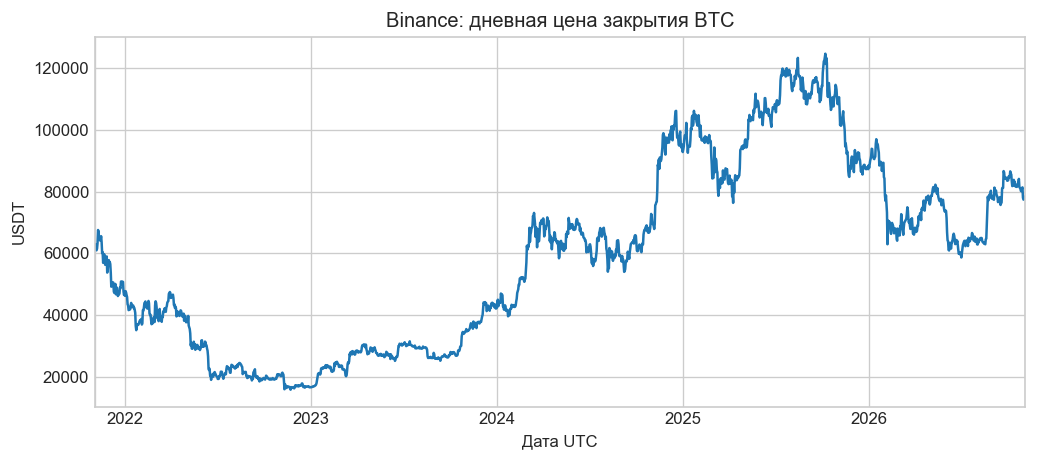

In [20]:
day_close.plot()
plt.title('Binance: дневная цена закрытия BTC')
plt.ylabel('USDT')
plt.xlabel('Дата UTC')
plt.show()

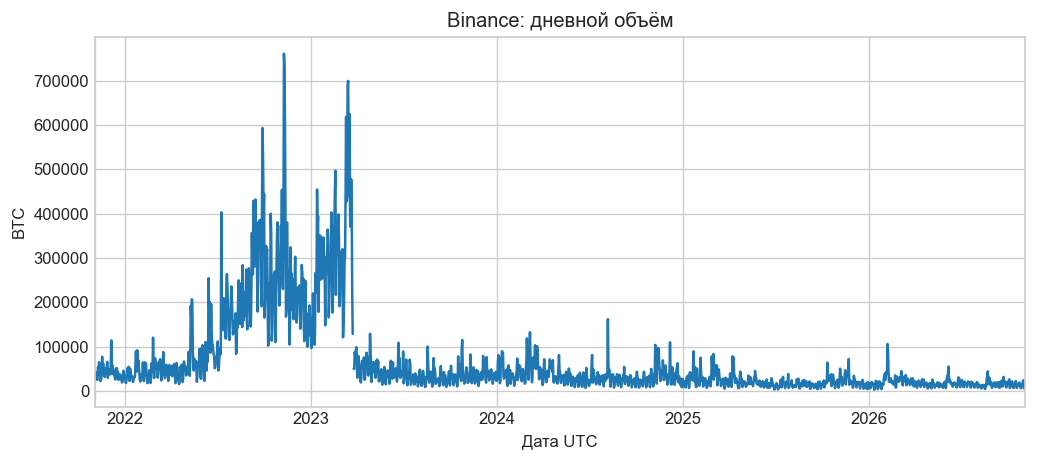

In [21]:
day_volume = btc['volume_base'].resample('D').sum()
day_volume = day_volume.where(day_count == 1440)
day_volume.index = day_volume.index + pd.Timedelta(days=1)
day_volume.plot()
plt.title('Binance: дневной объём')
plt.ylabel('BTC')
plt.xlabel('Дата UTC')
plt.show()

## 6. Доходности

Считаем изменение close относительно предыдущего close в процентах. `fill_method=None` нужен, чтобы pandas не заполнял пропущенные цены. Если соседняя свеча недоступна, доходность не рассчитывается.

Четырёхчасовые изменения здесь идут по последовательным четырёхчасовым свечам и не перекрываются.

In [22]:
minute_return = btc['close'].pct_change(fill_method=None) * 100
hour_return = hour_close.pct_change(fill_method=None) * 100
four_hour_return = four_hour_close.pct_change(fill_method=None) * 100
day_return = day_close.pct_change(fill_method=None) * 100

In [23]:
pd.DataFrame({
    '1 минута': minute_return.describe(),
    '1 час': hour_return.describe(),
    '4 часа': four_hour_return.describe(),
    '1 день': day_return.describe()
}).round(4)

,1 минута,1 час,4 часа,1 день
count,2.629358e+06,43819.0000,10952.0000,1822.0000
mean,0.000000e+00,0.0019,0.0075,0.0491
std,7.190000e-02,0.5390,1.0577,2.6587
min,-5.510800e+00,-6.9890,-9.1486,-15.3798
25%,-2.690000e-02,-0.2055,-0.4100,-1.1889
50%,0.000000e+00,0.0029,0.0119,-0.0146
75%,2.680000e-02,0.2140,0.4298,1.2450
max,4.980400e+00,6.4872,8.4820,14.4856


На гистограмме оставлены все доступные часовые изменения, включая экстремальные. Логарифмическая ось количества наблюдений помогает увидеть редкие движения.

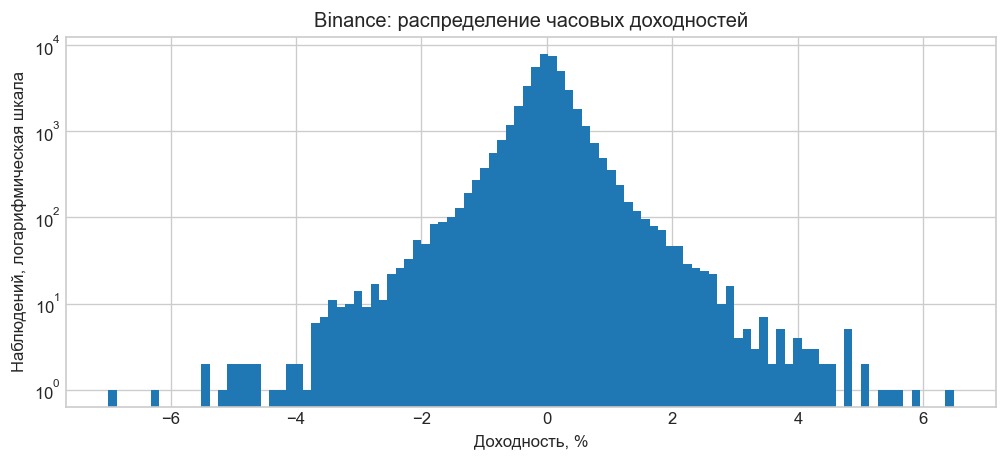

In [24]:
hour_return.hist(bins=100)
plt.yscale('log')
plt.title('Binance: распределение часовых доходностей')
plt.xlabel('Доходность, %')
plt.ylabel('Наблюдений, логарифмическая шкала')
plt.show()

In [25]:
hour_return.quantile([0.01, 0.5, 0.99])

0.01   -1.637593
0.50    0.002885
0.99    1.603738
Name: close, dtype: float64

Посмотрим пять самых больших минутных движений по модулю. В таблице сохраняем знак доходности. Дата означает начало текущей минутной свечи; её close известен через минуту.

In [26]:
dates = minute_return.abs().nlargest(5).index
big_moves = btc.loc[dates, ['open', 'high', 'low', 'close']].copy()
big_moves['Доходность, %'] = minute_return.loc[dates]
big_moves.round(4)

,open,high,low,close,"Доходность, %"
datetime_utc,,,,,
2022-09-21 18:00:00+00:00,19867.91,19956.00,18688.00,18773.04,-5.5108
2021-12-04 05:28:00+00:00,42463.28,46012.26,42244.33,44597.50,4.9804
2022-11-08 19:34:00+00:00,17367.62,18274.11,17320.97,18158.02,4.5782
2021-12-04 05:27:00+00:00,44502.41,44787.97,42000.30,42481.72,-4.5407
2022-11-10 13:30:00+00:00,16634.84,17384.37,16548.14,17371.73,4.4298


## 7. Волатильность

Волатильность — стандартное отклонение часовых доходностей за последние 24 часа и 7 дней. Это проценты часовой доходности, без пересчёта в год. Неполное окно не рассчитывается.

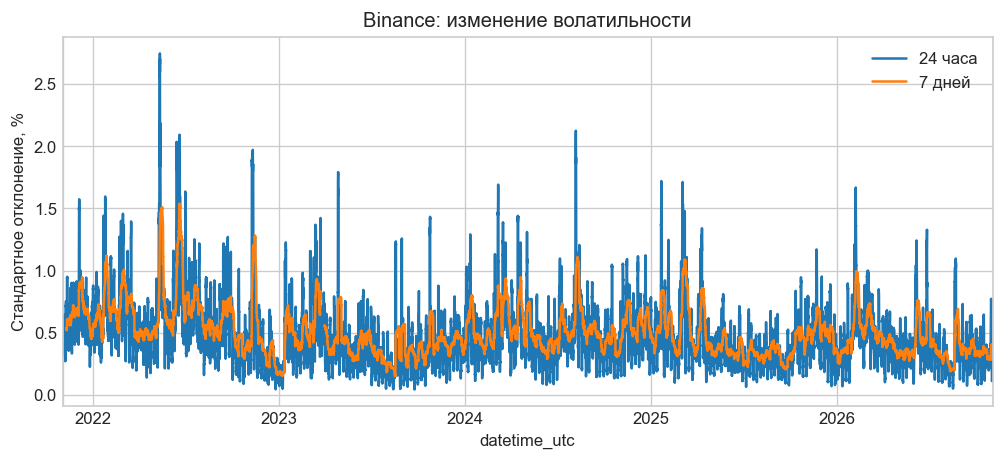

In [27]:
volatility_day = hour_return.rolling(24).std()
volatility_week = hour_return.rolling(168).std()
volatility_day.plot(label='24 часа')
volatility_week.plot(label='7 дней')
plt.title('Binance: изменение волатильности')
plt.ylabel('Стандартное отклонение, %')
plt.legend()
plt.show()

Сравним годовые срезы. Первый и последний годы охвачены не полностью.

In [28]:
hour_return.groupby(hour_return.index.year).describe().round(4)

,count,mean,std,min,25%,50%,75%,max
datetime_utc,,,,,,,,
2021,1429.0,-0.0194,0.6628,-5.4094,-0.3670,-0.0321,0.3253,3.4334
2022,8760.0,-0.0094,0.6811,-6.9890,-0.2669,-0.0020,0.2551,6.4872
2023,8757.0,0.0118,0.4542,-6.2448,-0.1531,0.0080,0.1703,5.5275
2024,8784.0,0.0106,0.5617,-4.5873,-0.2277,0.0090,0.2569,4.3109
2025,8760.0,0.0004,0.4748,-4.8956,-0.1944,0.0026,0.2057,5.0270
2026,7329.0,-0.0006,0.4498,-4.8231,-0.1899,-0.0005,0.1849,3.9907


## 8. Объёмы и время активности

Нулевой объём — наблюдаемая свеча, а не пропущенная минута. Посмотрим обычный масштаб объёмов и долю активности в 1% самых крупных минут.

In [29]:
btc['volume_base'].describe()

count    2.629360e+06
mean     4.511694e+01
std      9.860219e+01
min      0.000000e+00
25%      5.996410e+00
50%      1.433973e+01
75%      3.970629e+01
max      5.877775e+03
Name: volume_base, dtype: float64

In [30]:
print('Минут с нулевым объёмом:', (btc['volume_base'] == 0).sum())
top_minutes = round(btc['close'].count() * 0.01)
top_volume = btc['volume_base'].nlargest(top_minutes).sum()
top_share = 100 * top_volume / btc['volume_base'].sum()
print('Доля объёма в верхнем 1% минут, %:', round(top_share, 2))

Минут с нулевым объёмом: 72
Доля объёма в верхнем 1% минут, %: 15.83


Сравним средний объём полных часов в разные часы UTC и дни недели. Для группировки используем начало часа, хотя часовая цена выше помечена временем закрытия.

In [31]:
hour_volume = btc['volume_base'].resample('h').sum()
hour_volume = hour_volume.where(hour_count == 60)
hour_start = hour_volume.index

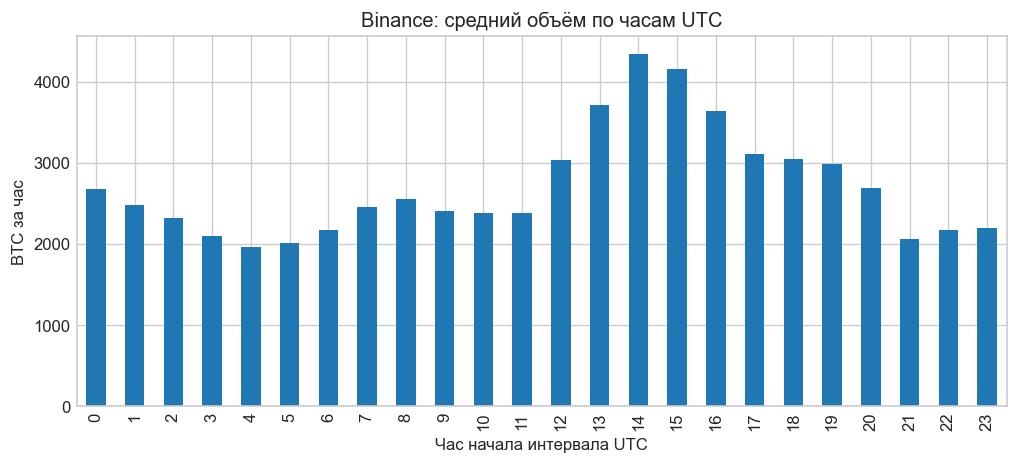

In [32]:
hour_volume.groupby(hour_start.hour).mean().plot.bar()
plt.title('Binance: средний объём по часам UTC')
plt.xlabel('Час начала интервала UTC')
plt.ylabel('BTC за час')
plt.show()

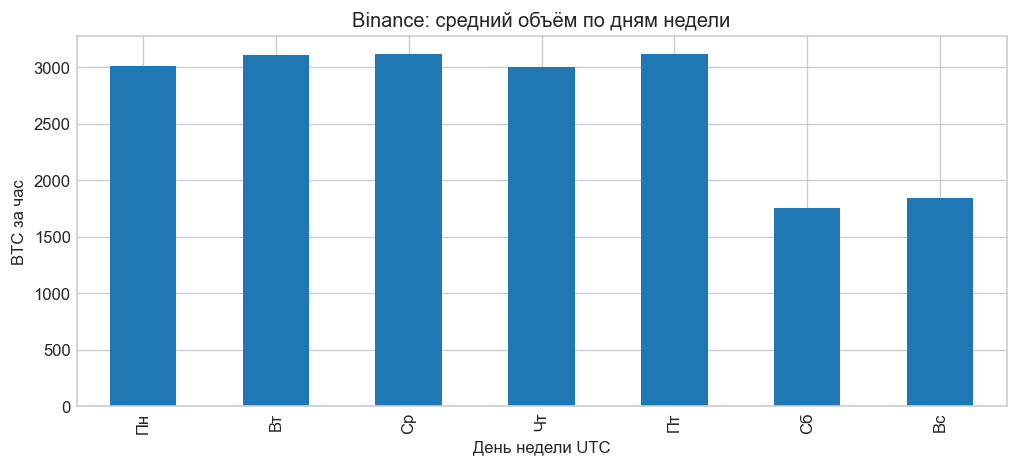

In [33]:
weekday_volume = hour_volume.groupby(hour_start.dayofweek).mean()
weekday_volume.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_volume.plot.bar()
plt.title('Binance: средний объём по дням недели')
plt.xlabel('День недели UTC')
plt.ylabel('BTC за час')
plt.show()

## 9. Связь соседних изменений

Проверяем корреляцию часовой доходности с её значениями 1, 4 и 24 часа назад. Для модуля доходности это показывает, следуют ли активные часы за активными. Сетка остаётся регулярной: пропуски не сдвигают лаги.

Это описание прошлой истории, а не проверка торгового сигнала.

In [34]:
pd.Series({
    'Лаг 1 час': hour_return.autocorr(1),
    'Лаг 4 часа': hour_return.autocorr(4),
    'Лаг 24 часа': hour_return.autocorr(24)
}).round(4)

Лаг 1 час     -0.0071
Лаг 4 часа     0.0030
Лаг 24 часа   -0.0168
dtype: float64

То же самое для модуля доходности:

In [35]:
absolute_return = hour_return.abs()
pd.Series({
    'Лаг 1 час': absolute_return.autocorr(1),
    'Лаг 4 часа': absolute_return.autocorr(4),
    'Лаг 24 часа': absolute_return.autocorr(24)
}).round(4)

Лаг 1 час      0.2804
Лаг 4 часа     0.1752
Лаг 24 часа    0.1638
dtype: float64